# Octavio Vieyra Orozco

| Columna | Tipo de dato | ¿Qué representa? |
|---|---|---|
| `Administrative` | Entero (`int64`) | Cantidad de páginas administrativas visitadas, como las relacionadas con la cuenta del usuario. |
| `Administrative_Duration` | Decimal (`float64`) | Tiempo total dedicado a páginas administrativas, en segundos. |
| `Informational` | Entero (`int64`) | Cantidad de páginas informativas visitadas, como información sobre la tienda. |
| `Informational_Duration` | Decimal (`float64`) | Tiempo total dedicado a páginas informativas, en segundos. |
| `ProductRelated` | Entero (`int64`) | Cantidad de páginas relacionadas con productos visitadas. |
| `ProductRelated_Duration` | Decimal (`float64`) | Tiempo total dedicado a páginas de productos, en segundos. |
| `BounceRates` | Decimal (`float64`) | Tasa de rebote de las páginas visitadas: proporción de visitas que terminan sin otra interacción. |
| `ExitRates` | Decimal (`float64`) | Tasa de salida de las páginas visitadas: proporción de vistas en las que una página fue la última de la sesión. |
| `PageValues` | Decimal (`float64`) | Valor promedio atribuido a las páginas visitadas antes de completar una compra. |
| `SpecialDay` | Decimal (`float64`) | Indicador de cercanía a una fecha comercial especial. Toma valores entre 0 y 1. |
| `Month` | Texto (`object`), categórica | Mes en que ocurrió la sesión. |
| `OperatingSystems` | Entero (`int64`), categórica | Código del sistema operativo utilizado. Los números representan categorías. |
| `Browser` | Entero (`int64`), categórica | Código del navegador utilizado. Los números representan categorías. |
| `Region` | Entero (`int64`), categórica | Código de la región del visitante. |
| `TrafficType` | Entero (`int64`), categórica | Código del tipo o fuente de tráfico por el que llegó el visitante. |
| `VisitorType` | Texto (`object`), categórica | Tipo de visitante: nuevo, recurrente u otro. |
| `Weekend` | Booleano (`bool`) | Indica si la sesión ocurrió en fin de semana: `True` significa sí y `False`, no. |
| `Revenue` | Booleano (`bool`) | Indica si la sesión terminó en una compra: `True` significa sí y `False`, no. No representa un importe monetario. |

In [1]:
!pip -q install kagglehub

In [2]:
# librerias
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
import kagglehub
import pandas as pd
import os
from pathlib import Path

# Descargar el dataset dentro de Colab
path = Path(
    kagglehub.dataset_download(
        "imakash3011/online-shoppers-purchasing-intention-dataset"
    )
)

# Encontrar y leer el archivo CSV
csv_path = next(path.rglob("*.csv"))
df = pd.read_csv(csv_path)

Using Colab cache for faster access to the 'online-shoppers-purchasing-intention-dataset' dataset.


In [4]:
# Dimensiones del Dataset
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 12330
Columnas: 18


In [5]:
# Primera filas del Dataset
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.00,0,0.00,1,0.00,0.20,0.20,0.00,0.00,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.00,0,0.00,2,64.00,0.00,0.10,0.00,0.00,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.00,0,0.00,1,0.00,0.20,0.20,0.00,0.00,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.00,0,0.00,2,2.67,0.05,0.14,0.00,0.00,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.00,0,0.00,10,627.50,0.02,0.05,0.00,0.00,Feb,3,3,1,4,Returning_Visitor,True,False


In [6]:
# Información del dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [7]:
# Calcula el número de valores únicos por columna y los ordena de forma descendente (de mayor a menor)
cardinalidad = df.nunique().sort_values(ascending=False)
# Muestra el resultado en pantalla
cardinalidad

,0
ProductRelated_Duration,9551
ExitRates,4777
Administrative_Duration,3335
PageValues,2704
BounceRates,1872
Informational_Duration,1258
ProductRelated,311
Administrative,27
TrafficType,20
Informational,17


In [8]:
# Describe variables cuantitativas
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,"12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00","12,330.00"
mean,2.32,80.82,0.50,34.47,31.73,"1,194.75",0.02,0.04,5.89,0.06,2.12,2.36,3.15,4.07
std,3.32,176.78,1.27,140.75,44.48,"1,913.67",0.05,0.05,18.57,0.20,0.91,1.72,2.40,4.03
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
25%,0.00,0.00,0.00,0.00,7.00,184.14,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00
50%,1.00,7.50,0.00,0.00,18.00,598.94,0.00,0.03,0.00,0.00,2.00,2.00,3.00,2.00
75%,4.00,93.26,0.00,0.00,38.00,"1,464.16",0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00
max,27.00,"3,398.75",24.00,"2,549.38",705.00,"63,973.52",0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00


In [9]:
# Describe variables cualitativas
df.describe(include="object")

,Month,VisitorType
count,12330,12330
unique,10,3
top,May,Returning_Visitor
freq,3364,10551


In [10]:
# Cardinalidad de los datos
# Calcula el número de valores únicos por columna y los ordena de forma descendente (de mayor a menor)
cardinalidad = df.nunique().sort_values(ascending=False)
# Muestra el resultado en pantalla
cardinalidad

,0
ProductRelated_Duration,9551
ExitRates,4777
Administrative_Duration,3335
PageValues,2704
BounceRates,1872
Informational_Duration,1258
ProductRelated,311
Administrative,27
TrafficType,20
Informational,17


## Comprensión de los Datos

### Duplicados
Dado que la cantidad de duplicados es demasiado baja, el eliminar estos no afectaria la callidad del dataset y el tener pocos datos repetidos en este tipo de data set donde es el seguimiento de un cliente que compran en linea y toma datos como el tiempo es muy poco probable que haya datos repetidos o que haya registros con los mismos datos en todas las columnas, dando a entender que en este caso los repetidos si son repetidos.

In [11]:
# Conteo de Duplicados
duplicados = df.duplicated().sum()
print("Registros duplicados:", duplicados)

Registros duplicados: 125


In [12]:
nulos = df.isna().sum().sort_values(ascending=False)
nulos[nulos > 0]

,0


In [13]:
# Trafic Type
df["TrafficType"].value_counts()

,count
TrafficType,
2,3913
1,2451
3,2052
4,1069
13,738
10,450
6,444
8,343
5,260


In [14]:
# Browser
df["Browser"].value_counts()

,count
Browser,
2,7961
1,2462
4,736
5,467
6,174
10,163
8,135
3,105
13,61


In [15]:
# Moths
df["Month"].value_counts()

,count
Month,
May,3364
Nov,2998
Mar,1907
Dec,1727
Oct,549
Sep,448
Aug,433
Jul,432
June,288


In [16]:
# Region
df["Region"].value_counts()

,count
Region,
1,4780
3,2403
4,1182
2,1136
6,805
7,761
9,511
8,434
5,318


In [17]:
# Operating System
df["OperatingSystems"].value_counts()

,count
OperatingSystems,
2,6601
1,2585
3,2555
4,478
8,79
6,19
7,7
5,6


In [18]:
# Special Days
df["SpecialDay"].value_counts()

,count
SpecialDay,
0.00,11079
0.60,351
0.80,325
0.40,243
0.20,178
1.00,154


In [19]:
# Visitor Type
df["VisitorType"].value_counts()

,count
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85


In [20]:
# Weekend
df["Weekend"].value_counts()

,count
Weekend,
False,9462
True,2868


In [21]:
# Revenue
df["Revenue"].value_counts()

,count
Revenue,
False,10422
True,1908


## Limpieza de los Datos

In [22]:
# Copia del Dataframe para limpiar los datos
df_copy = df.copy()


In [23]:
# Eliminar los duplicados
df_copy = df_copy.drop_duplicates()
# Cantidad de datos despues de eliminar duplicados
print("Registros duplicados:", df_copy.duplicated().sum())

Registros duplicados: 0


In [24]:
# Cantidad de registros
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12205 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  object 
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType              12

In [25]:
# Crear Variables auxiliares
# Segundos a minutos
df_copy["Administrative_Duration_min"] = df_copy["Administrative_Duration"] / 60
df_copy["Informational_Duration_min"] = df_copy["Informational_Duration"] / 60
df_copy["ProductRelated_Duration_min"] = df_copy["ProductRelated_Duration"] / 60
# Tiempo total en segundos y minutos
df_copy["Total_Duration_sec"] = df_copy["Administrative_Duration"] + df_copy["Informational_Duration"] + df_copy["ProductRelated_Duration"]
df_copy["Total_Duration_min"] = df_copy["Total_Duration_sec"] / 60
# Páginas totales
df_copy["Total_Pages"] = df_copy["Administrative"] + df_copy["Informational"] + df_copy["ProductRelated"]
# Muestras de las variables creadas
df_copy[["Total_Duration_sec", "Total_Duration_min", "Total_Pages"]].head(10)


,Total_Duration_sec,Total_Duration_min,Total_Pages
0,0.00,0.00,1
1,64.00,1.07,2
2,0.00,0.00,1
3,2.67,0.04,2
4,627.50,10.46,10
5,154.22,2.57,19
6,0.00,0.00,1
7,0.00,0.00,1
8,37.00,0.62,2
9,738.00,12.30,3


In [26]:
#Variable auxiliar para Meses en numerico
df_copy["Month No"] = df_copy["Month"].map({
    "Feb": 2, "Mar": 3, "May": 5, "June": 6, "Jul": 7,
    "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12
})
display(df_copy[["Month", "Month No"]].head(10))

,Month,Month No
0,Feb,2
1,Feb,2
2,Feb,2
3,Feb,2
4,Feb,2
5,Feb,2
6,Feb,2
7,Feb,2
8,Feb,2
9,Feb,2


#Patrones Básicos

¿Qué perfiles de navegación existen y cómo cambia el porcentaje de compra entre ellos?

## Frecuencias Absolutas y Relativas

VisitorType

La mayoría de las sesiones pertenece a visitantes recurrentes (aproximadamente 85%). Los visitantes nuevos representan cerca del 14% y la categoría “Other” aparece muy pocas veces. Esto indica que el sitio recibe principalmente usuarios que ya lo habían visitado anteriormente.

In [27]:
# Porcentajes y Frecuencia de Visitor type
segment_freq = df_copy["VisitorType"].value_counts()

segment_table = pd.DataFrame({
    "frecuencia": segment_freq,
    "proporcion": segment_freq / segment_freq.sum(),
    "porcentaje": segment_freq / segment_freq.sum() * 100
})

segment_table.round(3)

,frecuencia,proporcion,porcentaje
VisitorType,,,
Returning_Visitor,10431,0.85,85.47
New_Visitor,1693,0.14,13.87
Other,81,0.01,0.66


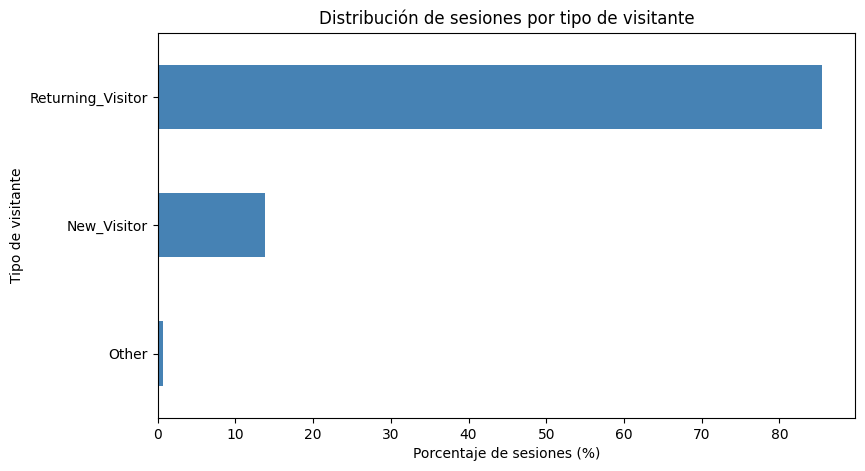

In [28]:
# Gráfico de distribución por tipo de visitante

segment_table["porcentaje"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.xlabel("Porcentaje de sesiones (%)")
plt.ylabel("Tipo de visitante")
plt.title("Distribución de sesiones por tipo de visitante")
plt.show()

Revenue

Aproximadamente el 84% de las sesiones no terminó en una compra, mientras que cerca del 16% sí generó una compra. Esto muestra que concretar una compra es menos frecuente que abandonar el sitio sin comprar.

In [29]:
# Porcentaje y Frecuencia de Revenue
segment_freq_rev = df_copy["Revenue"].value_counts()

segment_table_rev = pd.DataFrame({
    "frecuencia": segment_freq_rev,
    "proporcion": segment_freq_rev / segment_freq_rev.sum(),
    "porcentaje": segment_freq_rev / segment_freq_rev.sum() * 100
})

segment_table_rev.round(3)

,frecuencia,proporcion,porcentaje
Revenue,,,
False,10297,0.84,84.37
True,1908,0.16,15.63


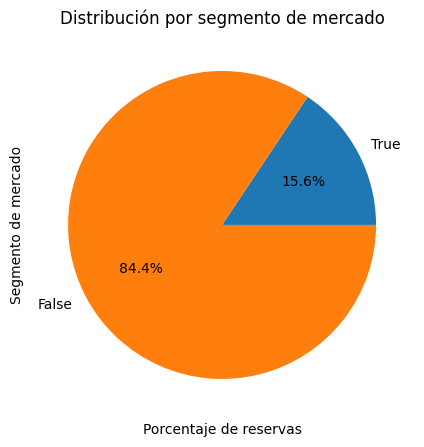

In [30]:
# Grafico de segmentos Revenue
segment_table_rev["porcentaje"].sort_values().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(9,5)
)

plt.xlabel("Porcentaje de reservas")
plt.ylabel("Segmento de mercado")
plt.title("Distribución por segmento de mercado")
plt.show()

Weekend

Cerca del 77% de las sesiones ocurrió entre semana y alrededor del 23% durante el fin de semana. Por lo tanto, el sitio recibe más actividad en días laborales, aunque esto todavía no indica en qué periodo existe una mayor probabilidad de compra.

In [31]:
# Porcentajes y Frecuencia de Weekend
segment_freq_weekend = df_copy["Weekend"].value_counts()

segment_table_weekend = pd.DataFrame({
    "frecuencia": segment_freq_weekend,
    "proporcion": segment_freq_weekend / segment_freq_weekend.sum(),
    "porcentaje": segment_freq_weekend / segment_freq_weekend.sum() * 100
})

segment_table_weekend.round(3)

,frecuencia,proporcion,porcentaje
Weekend,,,
False,9346,0.77,76.58
True,2859,0.23,23.43


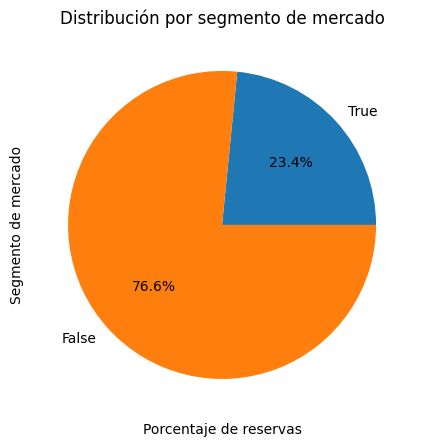

In [32]:
# Grafico de segmentos Weenkend
segment_table_weekend["porcentaje"].sort_values().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(9,5)
)
plt.xlabel("Porcentaje de reservas")
plt.ylabel("Segmento de mercado")
plt.title("Distribución por segmento de mercado")
plt.show()

## Perfiles y Comparación de Grupos

Perfil de Visitante

In [33]:
perfil_visitantes = df_copy.groupby("VisitorType").agg(
    sesiones=("VisitorType", "size"),
    promedio_paginas=("Total_Pages", "mean"),
    promedio_duracion_min=("Total_Duration_min", "mean"),
    mediana_duracion_min=("Total_Duration_min", "median"), # porcentaje del grupo
    porcentaje_compra=("Revenue", lambda x: x.mean() * 100)
).round(2)

perfil_visitantes

,sesiones,promedio_paginas,promedio_duracion_min,mediana_duracion_min,porcentaje_compra
VisitorType,,,,,
New_Visitor,1693,20.95,12.47,8.37,24.93
Other,81,14.77,11.28,3.70,19.75
Returning_Visitor,10431,37.31,23.70,12.49,14.09


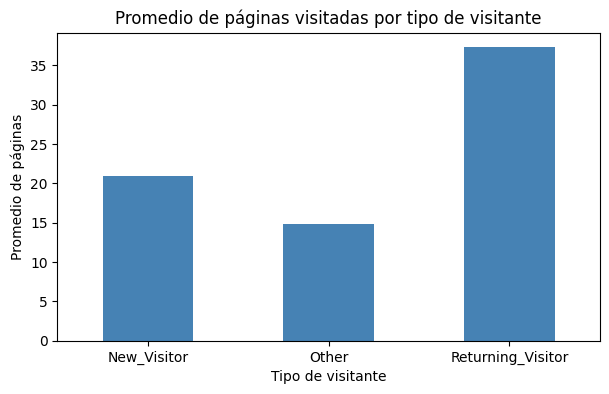

In [34]:
perfil_visitantes["promedio_paginas"].plot(
    kind="bar",
    color="steelblue",
    figsize=(7, 4)
)

plt.title("Promedio de páginas visitadas por tipo de visitante")
plt.xlabel("Tipo de visitante")
plt.ylabel("Promedio de páginas")
plt.xticks(rotation=0)
plt.show()

Interpretación Perfil Visitante

Los visitantes recurrentes representan la mayor parte del conjunto de datos, con 10,431 sesiones. También presentan el mayor nivel de interacción: consultan en promedio 37.31 páginas y permanecen aproximadamente 23.70 minutos. Sin embargo, su porcentaje de compra es el más bajo de los tres grupos, con 14.09%.
En contraste, los visitantes nuevos registran menos páginas consultadas y una duración promedio menor, pero alcanzan el porcentaje de compra más alto, con 24.93%. Esto indica que una mayor interacción o duración de la sesión no necesariamente se traduce en una mayor probabilidad de compra.
El grupo denominado “Other” presenta un porcentaje de compra de 19.75%, pero solamente contiene 81 sesiones. Debido a su reducido tamaño, sus resultados deben interpretarse con cautela y no necesariamente representan un patrón generalizable.
Los dos contrastes principales son:
1. Los visitantes recurrentes navegan más y permanecen más tiempo, pero convierten menos que los visitantes nuevos.
2. Los visitantes nuevos muestran una interacción menor, pero tienen una tasa de compra aproximadamente 10.84 puntos porcentuales superior a la de los visitantes recurrentes.

Perfil de Revenue

In [35]:
perfil_compra = df_copy.groupby("Revenue").agg(
    sesiones=("Revenue", "size"),
    promedio_paginas=("Total_Pages", "mean"),
    promedio_duracion_min=("Total_Duration_min", "mean"),
    proximidad_dia_especial=("SpecialDay", "mean"),
    paginas_administrativas=("Administrative", "mean"),
    paginas_informativas=("Informational", "mean"),
    paginas_de_productos=("ProductRelated", "mean")
).round(3)

perfil_compra.index = perfil_compra.index.map({
    False: "Sin compra",
    True: "Con compra"
})

perfil_compra

,sesiones,promedio_paginas,promedio_duracion_min,proximidad_dia_especial,paginas_administrativas,paginas_informativas,paginas_de_productos
Revenue,,,,,,,
Sin compra,10297,31.65,19.80,0.07,2.14,0.46,29.05
Con compra,1908,52.39,34.22,0.02,3.39,0.79,48.21


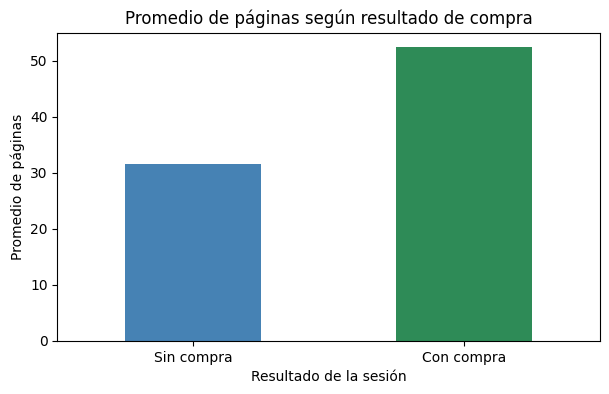

In [36]:
# Gráfico 1: promedio de páginas visitadas

perfil_compra["promedio_paginas"].plot(
    kind="bar",
    color=["steelblue", "seagreen"],
    figsize=(7, 4)
)

plt.title("Promedio de páginas según resultado de compra")
plt.xlabel("Resultado de la sesión")
plt.ylabel("Promedio de páginas")
plt.xticks(rotation=0)
plt.show()

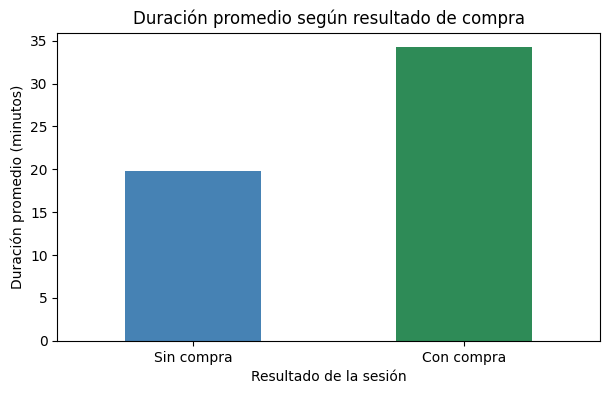

In [37]:
# Gráfico 2: duración promedio de la sesión

perfil_compra["promedio_duracion_min"].plot(
    kind="bar",
    color=["steelblue", "seagreen"],
    figsize=(7, 4)
)

plt.title("Duración promedio según resultado de compra")
plt.xlabel("Resultado de la sesión")
plt.ylabel("Duración promedio (minutos)")
plt.xticks(rotation=0)
plt.show()

Interpretación Perfil Revenue

Las sesiones sin compra son mayoría, con 10,297 registros, frente a 1,908 sesiones con compra. Sin embargo, los usuarios que compraron mostraron mayor interacción: visitaron en promedio 52.39 páginas y permanecieron 34.22 minutos, mientras que quienes no compraron visitaron 31.65 páginas durante 19.80 minutos.
Esta diferencia aparece en todos los tipos de páginas. Las sesiones con compra registraron más visitas a páginas administrativas, informativas y, principalmente, de productos, con 48.21 frente a 29.05. Por otro lado, la proximidad a días especiales fue menor en las sesiones con compra, por lo que no parece ser un factor determinante. En general, los resultados sugieren que una mayor navegación y permanencia en el sitio están relacionadas con la compra.

## Tablas Cruzadas

In [38]:
# Corsstab entre visitor type y revenue
crosstab_visitor_type_revenue = pd.crosstab(df_copy["VisitorType"], df_copy["Revenue"])
crosstab_visitor_type_revenue

Revenue,False,True
VisitorType,,
New_Visitor,1271,422
Other,65,16
Returning_Visitor,8961,1470


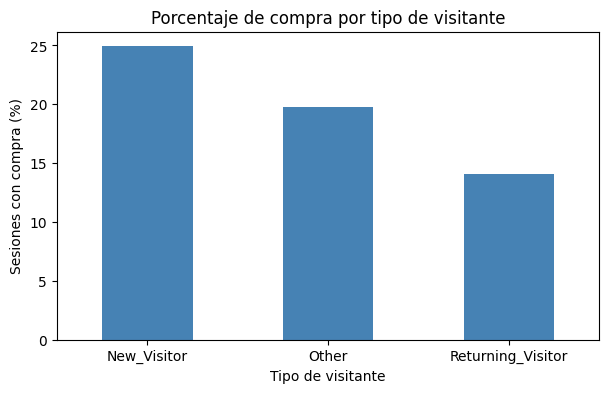

In [39]:
visitor_revenue_pct = pd.crosstab(
    df_copy["VisitorType"],
    df_copy["Revenue"],
    normalize="index"
)[True] * 100

visitor_revenue_pct.plot(
    kind="bar",
    color="steelblue",
    figsize=(7, 4)
)

plt.title("Porcentaje de compra por tipo de visitante")
plt.xlabel("Tipo de visitante")
plt.ylabel("Sesiones con compra (%)")
plt.xticks(rotation=0)
plt.show()

In [40]:
# Corsstab entre weekend y revenue
crosstab_weekend_revenue = pd.crosstab(df_copy["Weekend"], df_copy["Revenue"])
crosstab_weekend_revenue

Revenue,False,True
Weekend,,
False,7937,1409
True,2360,499


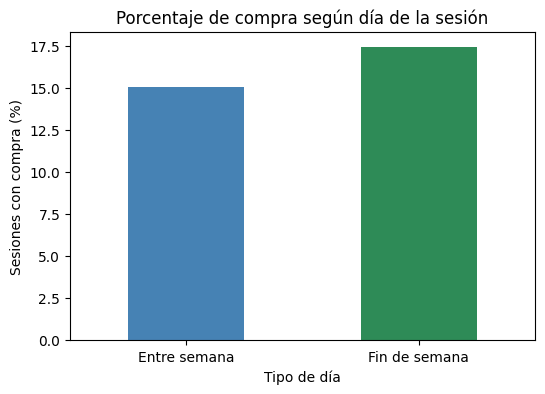

In [41]:
weekend_revenue_pct = pd.crosstab(
    df_copy["Weekend"],
    df_copy["Revenue"],
    normalize="index"
)[True] * 100

weekend_revenue_pct.index = weekend_revenue_pct.index.map({
    False: "Entre semana",
    True: "Fin de semana"
})

weekend_revenue_pct.plot(
    kind="bar",
    color=["steelblue", "seagreen"],
    figsize=(6, 4)
)

plt.title("Porcentaje de compra según día de la sesión")
plt.xlabel("Tipo de día")
plt.ylabel("Sesiones con compra (%)")
plt.xticks(rotation=0)
plt.show()

In [42]:
# Corsstab entre month y revenue
crosstab_month_revenue = pd.crosstab(df_copy["Month"], df_copy["Revenue"])
crosstab_month_revenue

Revenue,False,True
Month,,
Aug,357,76
Dec,1490,216
Feb,178,3
Jul,366,66
June,256,29
Mar,1668,192
May,2964,365
Nov,2222,760
Oct,434,115


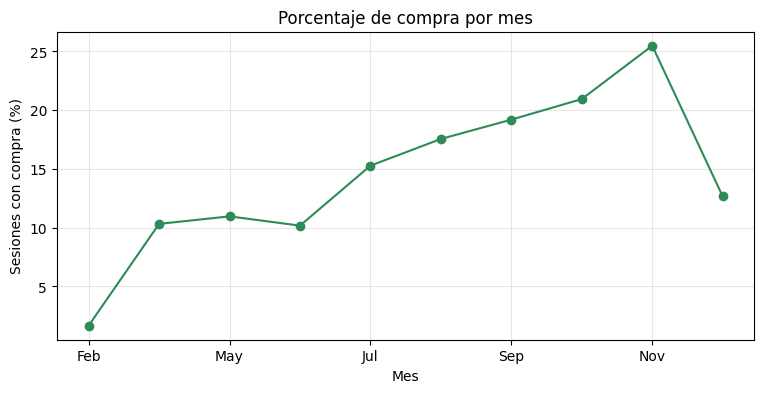

In [43]:
month_revenue_pct = pd.crosstab(
    df_copy["Month"],
    df_copy["Revenue"],
    normalize="index"
)[True] * 100

orden_meses = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

month_revenue_pct = month_revenue_pct.reindex(orden_meses)

month_revenue_pct.plot(
    kind="line",
    marker="o",
    color="seagreen",
    figsize=(9, 4)
)

plt.title("Porcentaje de compra por mes")
plt.xlabel("Mes")
plt.ylabel("Sesiones con compra (%)")
plt.grid(alpha=0.3)
plt.show()

# Construcción de Segmentos

## Creación de Categorías

In [44]:
df_copy["categoria_duracion"] = pd.cut(
    df_copy["Total_Duration_min"],
    bins=[-1, 15, 30, 45, 60, float("inf")],
    labels=[
        "Menos de 15 min",
        "15 a 30 min",
        "30 a 45 min",
        "45 a 60 min",
        "Más de 60 min"
    ],
    right=False
)

df_copy["categoria_duracion"].value_counts(sort=False)

,count
categoria_duracion,
Menos de 15 min,7028
15 a 30 min,2423
30 a 45 min,1167
45 a 60 min,600
Más de 60 min,987


In [45]:
perfil_duracion = (
    df_copy.groupby(
        "categoria_duracion",
        observed=True
    )
    .agg(
        sesiones=("Revenue", "size"),
        porcentaje_compra=("Revenue", lambda x: x.mean() * 100),
        promedio_paginas=("Total_Pages", "mean")
    )
    .round(2)
)

perfil_duracion

,sesiones,porcentaje_compra,promedio_paginas
categoria_duracion,,,
Menos de 15 min,7028,10.24,13.34
15 a 30 min,2423,20.35,36.21
30 a 45 min,1167,22.11,54.00
45 a 60 min,600,23.00,72.25
Más de 60 min,987,30.29,139.83


In [46]:
df_copy["nivel_navegacion"] = pd.qcut(
    df_copy["Total_Pages"],
    q=4,
    labels=[
        "baja",
        "media",
        "alta",
        "muy alta"
    ]
)

df_copy["nivel_navegacion"].value_counts(sort=False)

,count
nivel_navegacion,
baja,3290
media,2836
alta,3073
muy alta,3006


In [47]:
df_copy.groupby(
    "nivel_navegacion",
    observed=True
)["Total_Pages"].agg(["min", "max", "count"])

,min,max,count
nivel_navegacion,,,
baja,0,9,3290
media,10,20,2836
alta,21,42,3073
muy alta,43,746,3006


In [48]:
perfil_navegacion = (
    df_copy.groupby(
        "nivel_navegacion",
        observed=True
    )
    .agg(
        sesiones=("Revenue", "size"),
        promedio_paginas=("Total_Pages", "mean"),
        tasa_compra_categoria=("Revenue", lambda x: x.mean() * 100)
    )
    .round(2)
)

perfil_navegacion

,sesiones,promedio_paginas,tasa_compra_categoria
nivel_navegacion,,,
baja,3290,4.74,5.81
media,2836,14.71,13.89
alta,3073,30.06,19.59
muy alta,3006,91.88,23.99


## Segmentación por Reglas

In [49]:
# Límites obtenidos de la distribución de los datos

q25_paginas = df_copy["Total_Pages"].quantile(0.25)
q50_paginas = df_copy["Total_Pages"].quantile(0.50)
q75_paginas = df_copy["Total_Pages"].quantile(0.75)

q25_duracion = df_copy["Total_Duration_min"].quantile(0.25)
q50_duracion = df_copy["Total_Duration_min"].quantile(0.50)
q75_duracion = df_copy["Total_Duration_min"].quantile(0.75)

condiciones = [
    # Muchas páginas y larga duración
    (
        (df_copy["Total_Pages"] >= q75_paginas) &
        (df_copy["Total_Duration_min"] >= q75_duracion)
    ),

    # Ambas variables por encima de la mediana
    (
        (df_copy["Total_Pages"] >= q50_paginas) &
        (df_copy["Total_Duration_min"] >= q50_duracion)
    ),

    # Pocas páginas y corta duración
    (
        (df_copy["Total_Pages"] <= q25_paginas) &
        (df_copy["Total_Duration_min"] <= q25_duracion)
    )
]

segmentos = [
    "Interacción muy alta",
    "Interacción alta",
    "Interacción baja"
]

df_copy["nivel_interaccion"] = np.select(
    condiciones,
    segmentos,
    default="Interacción media"
)

perfil_interaccion = (
    df_copy.groupby("nivel_interaccion")
    .agg(
        sesiones=("Revenue", "size"),
        promedio_paginas=("Total_Pages", "mean"),
        promedio_duracion_min=("Total_Duration_min", "mean"),
        tasa_compra=("Revenue", lambda x: x.mean() * 100)
    )
    .round(2)
)

perfil_interaccion

,sesiones,promedio_paginas,promedio_duracion_min,tasa_compra
nivel_interaccion,,,,
Interacción alta,2958,36.90,23.32,21.91
Interacción baja,2510,4.15,1.20,4.06
Interacción media,4444,15.93,9.20,13.05
Interacción muy alta,2293,102.71,68.17,25.21


## Combinar dos categorías

In [50]:
df_copy["segmento_visitante_navegacion"] = (
    df_copy["VisitorType"].astype(str)
    + " | "
    + df_copy["nivel_navegacion"].astype(str)
)

In [51]:
perfil_visitante_navegacion = (
    df_copy.groupby("segmento_visitante_navegacion")
    .agg(
        sesiones=("Revenue", "size"),
        tasa_compra=("Revenue", lambda x: x.mean() * 100),
        duracion_promedio_min=("Total_Duration_min", "mean")
    )
    .round(2)
    .sort_values("tasa_compra", ascending=False)
)

perfil_visitante_navegacion

,sesiones,tasa_compra,duracion_promedio_min
segmento_visitante_navegacion,,,
Other | muy alta,5,80.00,58.62
Other | media,16,37.50,12.39
New_Visitor | muy alta,165,33.33,35.20
Other | alta,12,33.33,22.95
New_Visitor | alta,450,31.56,17.73
New_Visitor | media,623,23.76,9.04
Returning_Visitor | muy alta,2836,23.34,57.86
Returning_Visitor | alta,2611,17.46,20.12
New_Visitor | baja,455,16.92,3.71


In [52]:
tabla_visitante_navegacion = (
    df_copy.groupby(
        ["VisitorType", "nivel_navegacion"],
        observed=True
    )["Revenue"]
    .mean()
    .mul(100)
    .unstack()
    .round(2)
)

tabla_visitante_navegacion

nivel_navegacion,baja,media,alta,muy alta
VisitorType,,,,
New_Visitor,16.92,23.76,31.56,33.33
Other,4.17,37.50,33.33,80.00
Returning_Visitor,4.02,10.92,17.46,23.34


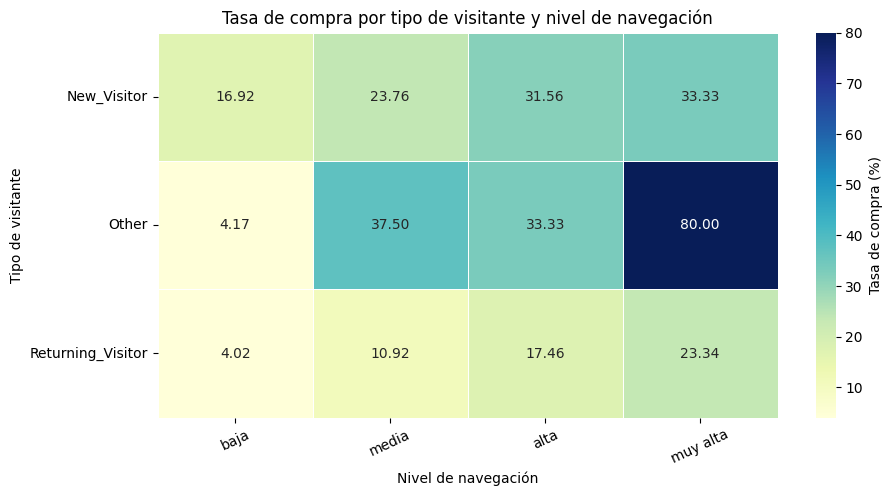

In [53]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    tabla_visitante_navegacion,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Tasa de compra (%)"}
)

plt.title("Tasa de compra por tipo de visitante y nivel de navegación")
plt.xlabel("Nivel de navegación")
plt.ylabel("Tipo de visitante")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.show()

## Visualización de Patrones

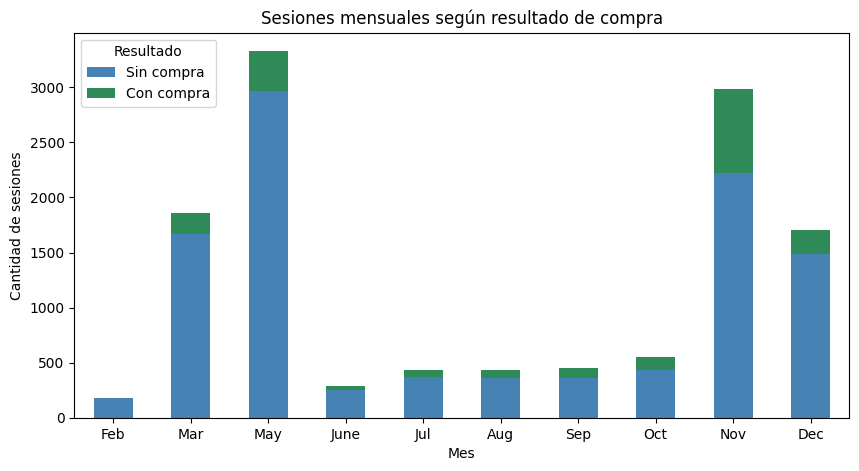

In [54]:
orden_meses = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

registros_mes = pd.crosstab(
    df_copy["Month"],
    df_copy["Revenue"]
).reindex(orden_meses)

registros_mes.columns = ["Sin compra", "Con compra"]

registros_mes.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["steelblue", "seagreen"]
)

plt.title("Sesiones mensuales según resultado de compra")
plt.xlabel("Mes")
plt.ylabel("Cantidad de sesiones")
plt.xticks(rotation=0)
plt.legend(title="Resultado")
plt.show()

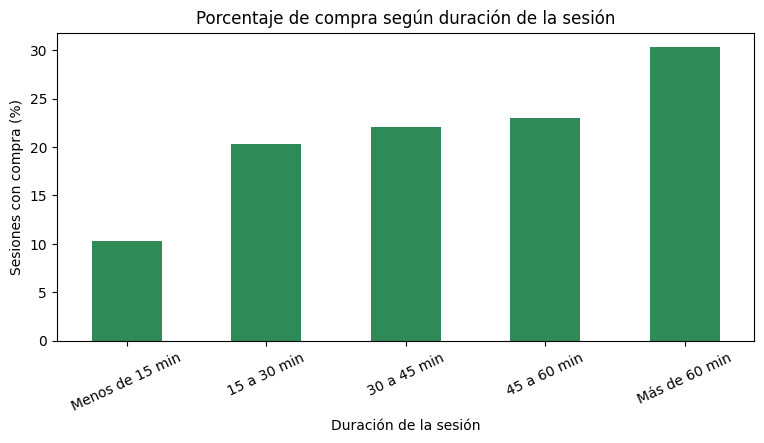

In [55]:
compra_por_duracion = (
    df_copy.groupby(
        "categoria_duracion",
        observed=True
    )["Revenue"]
    .mean()
    .mul(100)
)

compra_por_duracion.plot(
    kind="bar",
    color="seagreen",
    figsize=(9, 4)
)

plt.title("Porcentaje de compra según duración de la sesión")
plt.xlabel("Duración de la sesión")
plt.ylabel("Sesiones con compra (%)")
plt.xticks(rotation=25)
plt.show()

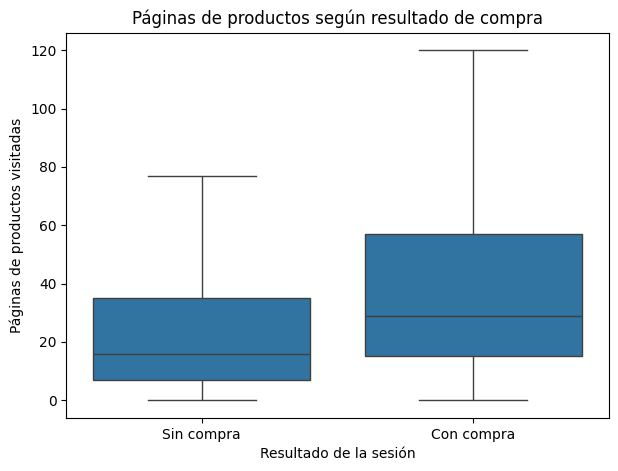

In [56]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_copy,
    x="Revenue",
    y="ProductRelated",
    showfliers=False
)

plt.title("Páginas de productos según resultado de compra")
plt.xlabel("Resultado de la sesión")
plt.ylabel("Páginas de productos visitadas")
plt.xticks([0, 1], ["Sin compra", "Con compra"])
plt.show()

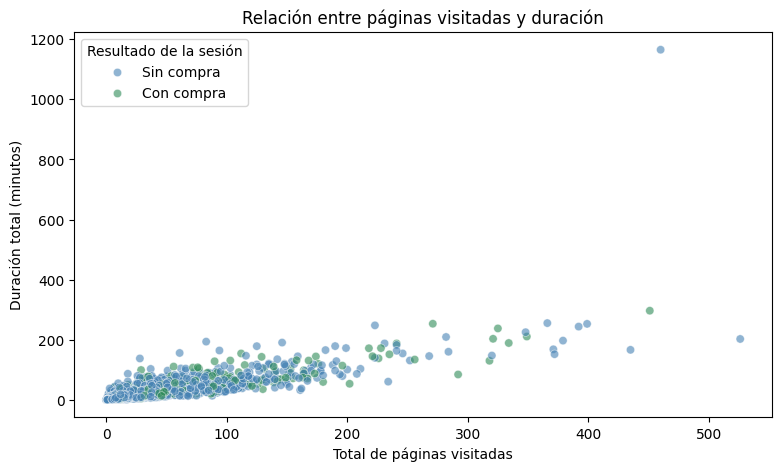

In [57]:
muestra = df_copy.sample(
    n=min(3000, len(df_copy)),
    random_state=42
).copy()

muestra["resultado_compra"] = muestra["Revenue"].map({
    False: "Sin compra",
    True: "Con compra"
})

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=muestra,
    x="Total_Pages",
    y="Total_Duration_min",
    hue="resultado_compra",
    palette={
        "Sin compra": "steelblue",
        "Con compra": "seagreen"
    },
    alpha=0.6
)

plt.title("Relación entre páginas visitadas y duración")
plt.xlabel("Total de páginas visitadas")
plt.ylabel("Duración total (minutos)")
plt.legend(title="Resultado de la sesión")
plt.show()
plt.show()

## Comportamientos Atípicos

### Percentiles

In [58]:
variables_percentiles = df_copy[[
    "Total_Duration_min",
    "Total_Pages",
    "ProductRelated"
]].copy()

variables_percentiles = variables_percentiles.rename(columns={
    "Total_Duration_min": "Duración total (min)",
    "Total_Pages": "Páginas totales",
    "ProductRelated": "Páginas de productos"
})

In [59]:
tabla_percentiles = variables_percentiles.quantile([
    0.01,
    0.05,
    0.25,
    0.50,
    0.75,
    0.95,
    0.99
]).T

tabla_percentiles.columns = [
    "P1",
    "P5",
    "P25",
    "P50",
    "P75",
    "P95",
    "P99"
]

tabla_percentiles.round(2)

,P1,P5,P25,P50,P75,P95,P99
Duración total (min),0.00,0.07,3.86,11.52,27.40,76.96,153.66
Páginas totales,1.00,2.00,9.00,20.00,42.00,117.00,231.96
Páginas de productos,1.00,2.00,8.00,18.00,38.00,110.00,221.00


- P1: el 1% de las sesiones tiene un valor igual o menor.
- P5: el 5% de las sesiones tiene un valor igual o menor.
- P25: el 25% de las sesiones se encuentra por debajo.
- P50 es la mediana: la mitad de las sesiones queda por debajo de ese valor.
- P75 indica que el 75% de las sesiones queda por debajo.
- P95 muestra el límite que solamente supera el 5% de las sesiones.
- P99 muestra los valores que únicamente supera el 1%.

Interpretación de los percentiles

La duración de las sesiones presenta una distribución muy desigual. El 25% dura hasta 3.86 minutos, la mitad hasta 11.52 minutos y el 75% hasta 27.40 minutos. Sin embargo, el 5% supera los 76.96 minutos y solo el 1% supera aproximadamente los 153.66 minutos, lo que muestra la existencia de sesiones excepcionalmente largas.

En cuanto a la navegación, la mitad de las sesiones registra hasta 20 páginas visitadas y el 75% hasta 42 páginas. En los valores superiores, el 5% supera las 117 páginas y el 1% se encuentra por encima de aproximadamente 232 páginas. Esto indica que una pequeña cantidad de usuarios navega mucho más que el resto.

Las páginas de productos presentan un comportamiento similar: la mediana es de 18 páginas, mientras que el 5% de las sesiones supera las 110 y el 1% las 221 páginas. Además, su cercanía con los valores de páginas totales indica que la mayor parte de la navegación del sitio se concentra en páginas de productos.

En general, las tres variables tienen valores altos poco frecuentes. Estos casos pueden representar usuarios con una exploración especialmente intensa y no necesariamente errores, por lo que el método IQR permitirá identificarlos para analizarlos con mayor detalle.

### IQR

In [60]:
variables_iqr = {
    "Total_Duration_min": "Duración total (min)",
    "Total_Pages": "Páginas totales",
    "ProductRelated": "Páginas de productos"
}

resultados_iqr = []

for variable, nombre in variables_iqr.items():

    q1 = df_copy[variable].quantile(0.25)
    q3 = df_copy[variable].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = (
        (df_copy[variable] < limite_inferior) |
        (df_copy[variable] > limite_superior)
    )

    resultados_iqr.append({
        "Variable": nombre,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Valores atípicos": atipicos.sum(),
        "Porcentaje atípico": atipicos.mean() * 100
    })

tabla_iqr = pd.DataFrame(resultados_iqr)

tabla_iqr.round(2)

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Valores atípicos,Porcentaje atípico
0,Duración total (min),3.86,27.40,23.54,-31.45,62.71,922,7.55
1,Páginas totales,9.00,42.00,33.00,-40.50,91.50,971,7.96
2,Páginas de productos,8.00,38.00,30.00,-37.00,83.00,1007,8.25


Interpretación del método IQR

El método IQR identificó como atípicas las sesiones que superan los siguientes límites:
- Más de 62.71 minutos de duración: 922 sesiones, equivalentes al 7.55%.
- Más de 91.5 páginas totales: 971 sesiones, equivalentes al 7.96%.
- Más de 83 páginas de productos: 1,007 sesiones, equivalentes al 8.25%.
Los límites inferiores son negativos, pero estas variables no pueden tomar valores negativos. Por lo tanto, todos los casos atípicos detectados corresponden a valores altos.
Al comparar estos resultados con los percentiles, los límites del IQR se encuentran por debajo del percentil 95. Esto explica que aproximadamente entre el 7% y el 8% de las sesiones sean clasificadas como atípicas. Los resultados confirman que las variables tienen una distribución sesgada: la mayoría de las sesiones presenta valores moderados, mientras que un grupo pequeño navega durante mucho más tiempo y visita muchas más páginas.


¿Qué debemos hacer con estos registros?

No recomiendo eliminarlos, porque parecen comportamientos posibles y no errores. Pueden representar usuarios con una exploración especialmente intensa y, por lo tanto, aportar información importante sobre la intención de compra.
La decisión sería:
1. Conservar todos los registros en el dataset original.
2. Utilizar los indicadores de atípicos para identificar y comparar estas sesiones.
3. Limitar visualmente los valores extremos cuando dificulten la lectura de una gráfica, sin eliminarlos.
4. Antes de aplicar K-Means, reducir su influencia mediante una transformación o limitación, porque este algoritmo es sensible a valores extremos.


Podemos comprobar si estas sesiones atípicas tienen una tasa de compra distinta:

In [61]:
variables_iqr = [
    "Total_Duration_min",
    "Total_Pages",
    "ProductRelated"
]

# Inicialmente ninguna sesión se considera atípica
df_copy["atipico_general"] = False

for variable in variables_iqr:

    q1 = df_copy[variable].quantile(0.25)
    q3 = df_copy[variable].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipico_variable = (
        (df_copy[variable] < limite_inferior) |
        (df_copy[variable] > limite_superior)
    )

    # Será True si es atípica en al menos una variable
    df_copy["atipico_general"] = (
        df_copy["atipico_general"] |
        atipico_variable
    )

In [62]:
perfil_atipicos = (
    df_copy.groupby("atipico_general")
    .agg(
        sesiones=("Revenue", "size"),
        tasa_compra=("Revenue", lambda x: x.mean() * 100),
        promedio_paginas=("Total_Pages", "mean"),
        promedio_duracion=("Total_Duration_min", "mean")
    )
    .round(2)
)

perfil_atipicos.index = perfil_atipicos.index.map({
    False: "Sesiones normales",
    True: "Sesiones atípicas"
})

perfil_atipicos

,sesiones,tasa_compra,promedio_paginas,promedio_duracion
atipico_general,,,,
Sesiones normales,10908,14.20,23.11,13.95
Sesiones atípicas,1297,27.68,133.97,90.21


Se identificaron 1,297 sesiones atípicas, mientras que 10,908 se clasificaron como normales. Las sesiones atípicas presentan una navegación mucho más intensa: visitan en promedio 133.97 páginas y duran 90.21 minutos, frente a 23.11 páginas y 13.95 minutos en las sesiones normales.
Además, su tasa de compra es de 27.68%, casi el doble del 14.20% registrado en las sesiones normales. Esto indica que los valores atípicos no parecen ser errores, sino usuarios con un alto nivel de interacción y una mayor intención de compra.

# Segmentación Automática

In [63]:
columnas_excluir = [
    # Totales creados
    "Total_Pages",
    "Total_Duration_sec",
    "Total_Duration_min",

    # Duraciones originales en segundos
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration"
]

df_segmentacion = (
    df_copy
    .drop(columns=columnas_excluir, errors="ignore")
    .copy()
)

df_segmentacion.head()

,Administrative,Informational,ProductRelated,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Administrative_Duration_min,Informational_Duration_min,ProductRelated_Duration_min,Month No,categoria_duracion,nivel_navegacion,nivel_interaccion,segmento_visitante_navegacion,atipico_general
0,0,0,1,0.20,0.20,0.00,0.00,Feb,1,1,1,1,Returning_Visitor,False,False,0.00,0.00,0.00,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False
1,0,0,2,0.00,0.10,0.00,0.00,Feb,2,2,1,2,Returning_Visitor,False,False,0.00,0.00,1.07,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False
2,0,0,1,0.20,0.20,0.00,0.00,Feb,4,1,9,3,Returning_Visitor,False,False,0.00,0.00,0.00,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False
3,0,0,2,0.05,0.14,0.00,0.00,Feb,3,2,2,4,Returning_Visitor,False,False,0.00,0.00,0.04,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False
4,0,0,10,0.02,0.05,0.00,0.00,Feb,3,3,1,4,Returning_Visitor,True,False,0.00,0.00,10.46,2,Menos de 15 min,media,Interacción media,Returning_Visitor | media,False


In [64]:
df_correlacion = df_segmentacion.select_dtypes(
    include=["number", "bool"]
).copy()

corr_matrix = df_correlacion.corr()

print("Variables incluidas en la correlación:")
print(df_correlacion.columns.tolist())

Variables incluidas en la correlación:
['Administrative', 'Informational', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'Revenue', 'Administrative_Duration_min', 'Informational_Duration_min', 'ProductRelated_Duration_min', 'Month No', 'atipico_general']


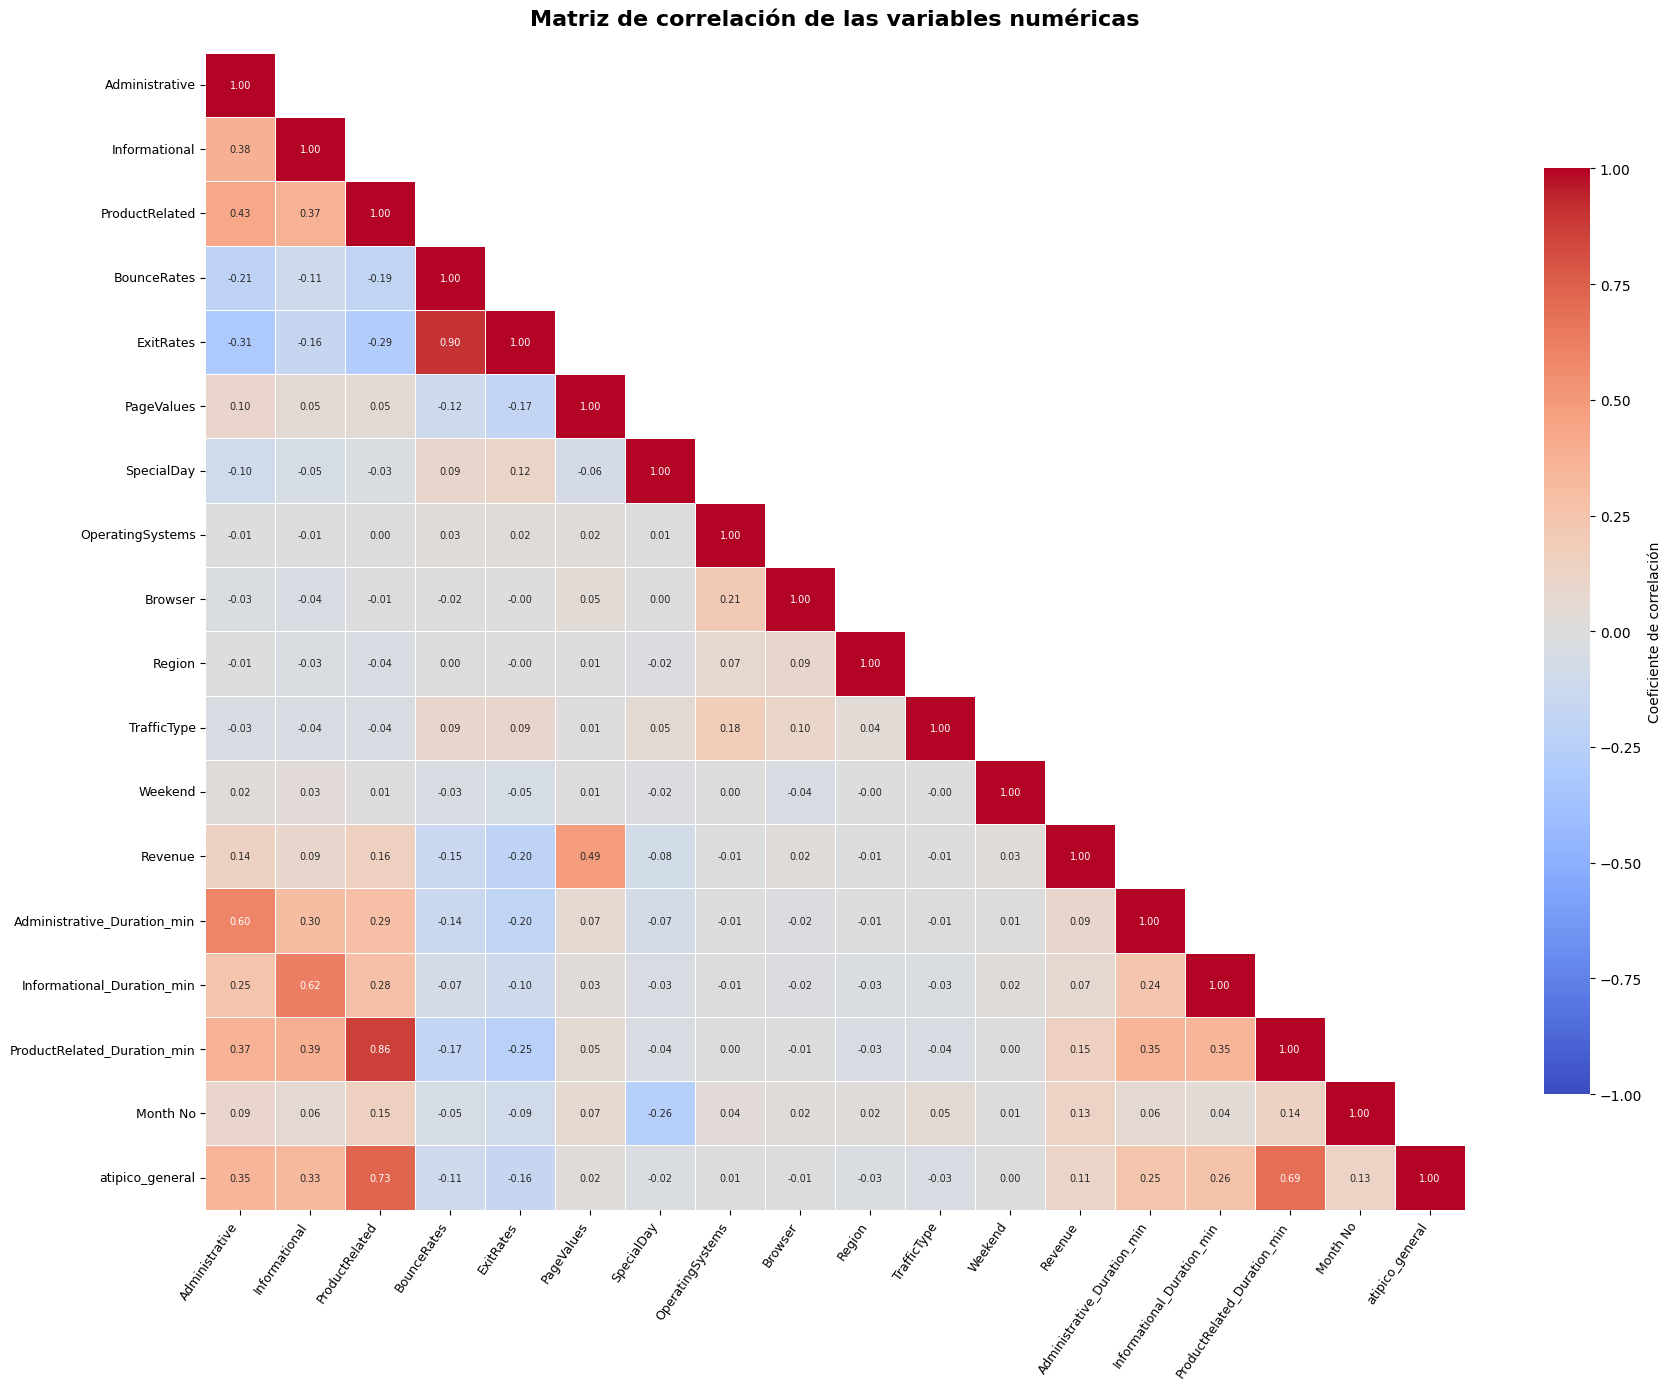

In [65]:
mascara = np.triu(
    np.ones_like(corr_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 7},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables numéricas",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=55, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

Se utilizó 0.80 como umbral porque, a partir de ese valor, la relación entre dos variables se considera suficientemente fuerte para sospechar que contienen información redundante. Eliminar una de ellas evita que un mismo comportamiento tenga doble peso en las distancias de K-Means. Las correlaciones menores a 0.80 se conservaron porque todavía pueden representar aspectos diferentes de la navegación.


El umbral podría ser 0.70 o 0.90 en otros proyectos; aquí 0.80 ofrece un equilibrio razonable entre reducir redundancia y conservar información útil.

In [66]:
# Seleccion de variables para dataset limpio
df_clean = df_segmentacion[[
    "Administrative",
    "Administrative_Duration_min",
    "Informational",
    "Informational_Duration_min",
    "ProductRelated"
]].copy()

df_clean.head()

,Administrative,Administrative_Duration_min,Informational,Informational_Duration_min,ProductRelated
0,0,0.00,0,0.00,1
1,0,0.00,0,0.00,2
2,0,0.00,0,0.00,1
3,0,0.00,0,0.00,2
4,0,0.00,0,0.00,10


In [67]:
print("Filas:", df_clean.shape[0])
print("Columnas:", df_clean.shape[1])
print("\nValores nulos:")
print(df_clean.isna().sum())

Filas: 12205
Columnas: 5

Valores nulos:
Administrative                 0
Administrative_Duration_min    0
Informational                  0
Informational_Duration_min     0
ProductRelated                 0
dtype: int64


## Similitud

##Distancia Euclidiana

In [68]:
A = np.array([20, 100])
B = np.array([30, 120])

distance = np.sqrt(
    np.sum((A - B) ** 2)
)

print("Distancia A-B:", round(distance,2))

Distancia A-B: 22.36


Una distancia menor implica mayor similitud **respecto a las variables utilizadas**.

La similitud depende de qué características elegimos.

## Escalas

La distancia euclidiana resume en un solo valor las diferencias entre las dos sesiones. Cada variable aporta una parte de la distancia: mientras mayor sea la diferencia en páginas visitadas o tiempo de navegación, mayor será la separación entre ambas sesiones.


Sin embargo, este resultado todavía se calcula con las escalas originales. Una variable con valores más grandes puede dominar la distancia, aunque no sea más importante. Por eso, antes de aplicar K-Means será necesario estandarizar las variables para que todas tengan una influencia comparable.

## Estandarización

In [69]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

df_scaled = pd.DataFrame(
    X_scaled,
    columns=df_clean.columns,
    index=df_clean.index
)

df_scaled.head()

,Administrative,Administrative_Duration_min,Informational,Informational_Duration_min,ProductRelated
0,-0.70,-0.46,-0.40,-0.25,-0.70
1,-0.70,-0.46,-0.40,-0.25,-0.67
2,-0.70,-0.46,-0.40,-0.25,-0.70
3,-0.70,-0.46,-0.40,-0.25,-0.67
4,-0.70,-0.46,-0.40,-0.25,-0.49


In [70]:
verificacion_escalas = pd.DataFrame({
    "Media": df_scaled.mean(),
    "Desviación estándar": df_scaled.std(ddof=0)
})

verificacion_escalas.round(2)

,Media,Desviación estándar
Administrative,-0.00,1.00
Administrative_Duration_min,-0.00,1.00
Informational,0.00,1.00
Informational_Duration_min,0.00,1.00
ProductRelated,-0.00,1.00


## Método del Codo

In [71]:
inercias = []
valores_k = range(2, 11)

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(df_scaled)
    inercias.append(modelo.inertia_)

In [72]:
tabla_codo = pd.DataFrame({
    "Número de clústeres": list(valores_k),
    "Inercia": inercias
})

tabla_codo.round(2)

,Número de clústeres,Inercia
0,2,"41,515.25"
1,3,"33,869.08"
2,4,"29,756.36"
3,5,"25,896.35"
4,6,"22,555.37"
5,7,"20,895.04"
6,8,"19,289.65"
7,9,"17,959.57"
8,10,"16,647.67"


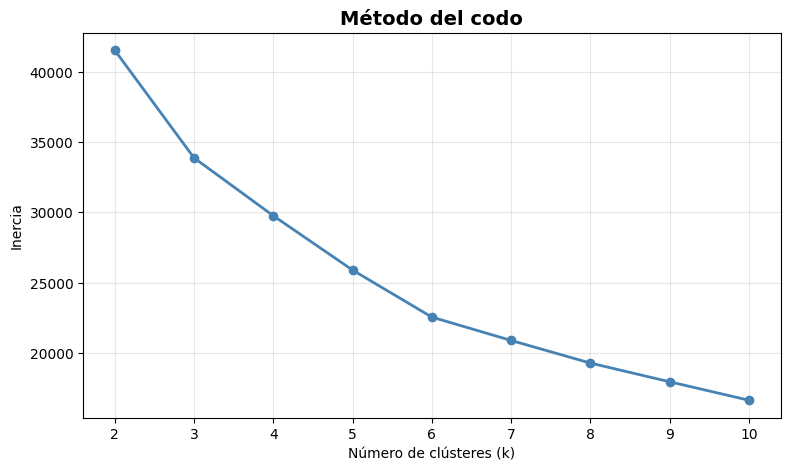

In [73]:
plt.figure(figsize=(9, 5))

plt.plot(
    valores_k,
    inercias,
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title(
    "Método del codo",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)

plt.show()

- De 2 a 3 clústeres: baja de 41,515.25 a 33,869.08, una reducción aproximada del 18.4%.
- De 3 a 4 clústeres: baja a 29,756.36, una reducción adicional del 12.1%.
- Después de 4, la disminución continúa, pero no aparece una mejora claramente excepcional.

## K-Means

In [74]:
# K-Means con 2 clústeres
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_2 = kmeans_2.fit_predict(df_scaled)


# K-Means con 3 clústeres
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_3 = kmeans_3.fit_predict(df_scaled)


# K-Means con 4 clústeres
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_4 = kmeans_4.fit_predict(df_scaled)

In [75]:
df_clusters = df_copy.loc[df_clean.index].copy()

df_clusters["cluster_k2"] = cluster_2
df_clusters["cluster_k3"] = cluster_3
df_clusters["cluster_k4"] = cluster_4

df_clusters.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Administrative_Duration_min,Informational_Duration_min,ProductRelated_Duration_min,Total_Duration_sec,Total_Duration_min,Total_Pages,Month No,categoria_duracion,nivel_navegacion,nivel_interaccion,segmento_visitante_navegacion,atipico_general,cluster_k2,cluster_k3,cluster_k4
0,0,0.00,0,0.00,1,0.00,0.20,0.20,0.00,0.00,Feb,1,1,1,1,Returning_Visitor,False,False,0.00,0.00,0.00,0.00,0.00,1,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False,0,0,1
1,0,0.00,0,0.00,2,64.00,0.00,0.10,0.00,0.00,Feb,2,2,1,2,Returning_Visitor,False,False,0.00,0.00,1.07,64.00,1.07,2,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False,0,0,1
2,0,0.00,0,0.00,1,0.00,0.20,0.20,0.00,0.00,Feb,4,1,9,3,Returning_Visitor,False,False,0.00,0.00,0.00,0.00,0.00,1,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False,0,0,1
3,0,0.00,0,0.00,2,2.67,0.05,0.14,0.00,0.00,Feb,3,2,2,4,Returning_Visitor,False,False,0.00,0.00,0.04,2.67,0.04,2,2,Menos de 15 min,baja,Interacción baja,Returning_Visitor | baja,False,0,0,1
4,0,0.00,0,0.00,10,627.50,0.02,0.05,0.00,0.00,Feb,3,3,1,4,Returning_Visitor,True,False,0.00,0.00,10.46,627.50,10.46,10,2,Menos de 15 min,media,Interacción media,Returning_Visitor | media,False,0,0,1


In [76]:
comparacion_clusters = pd.DataFrame({
    "K = 2": df_clusters["cluster_k2"].value_counts().sort_index(),
    "K = 3": df_clusters["cluster_k3"].value_counts().sort_index(),
    "K = 4": df_clusters["cluster_k4"].value_counts().sort_index()
}).fillna(0).astype(int)

comparacion_clusters

,K = 2,K = 3,K = 4
0,10439,9560,938
1,1766,2160,9136
2,0,485,1970
3,0,0,161


## Interpretación de Clusters

In [77]:
def perfil_kmeans(columna_cluster):
    return df_clusters.groupby(columna_cluster).agg(
        sesiones=("Revenue", "size"),
        paginas_administrativas=("Administrative", "mean"),
        tiempo_administrativo_min=("Administrative_Duration_min", "mean"),
        paginas_informativas=("Informational", "mean"),
        tiempo_informativo_min=("Informational_Duration_min", "mean"),
        paginas_productos=("ProductRelated", "mean"),
        porcentaje_compra=("Revenue", lambda x: x.mean() * 100)
    ).round(2)

In [78]:
perfil_k2 = perfil_kmeans("cluster_k2")
perfil_k2

,sesiones,paginas_administrativas,tiempo_administrativo_min,paginas_informativas,tiempo_informativo_min,paginas_productos,porcentaje_compra
cluster_k2,,,,,,,
0,10439,1.45,0.70,0.18,0.11,22.83,13.78
1,1766,7.61,5.28,2.43,3.38,86.50,26.61


In [79]:
comparacion_revenue = pd.crosstab(
    df_clusters["cluster_k2"],
    df_clusters["Revenue"],
    normalize="index"
).mul(100).round(2)

comparacion_revenue.columns = ["Sin compra", "Con compra"]

comparacion_revenue

,Sin compra,Con compra
cluster_k2,,
0,86.22,13.78
1,73.39,26.61


In [80]:
perfil_k3 = perfil_kmeans("cluster_k3")
perfil_k3

,sesiones,paginas_administrativas,tiempo_administrativo_min,paginas_informativas,tiempo_informativo_min,paginas_productos,porcentaje_compra
cluster_k3,,,,,,,
0,9560,1.02,0.46,0.18,0.11,20.92,13.11
1,2160,7.27,4.71,1.00,0.69,67.67,24.03
2,485,6.40,4.20,4.72,9.28,92.65,28.04


In [81]:
comparacion_revenue_k3 = pd.crosstab(
    df_clusters["cluster_k3"],
    df_clusters["Revenue"],
    normalize="index"
).mul(100).round(2)

comparacion_revenue_k3.columns = ["Sin compra", "Con compra"]

comparacion_revenue_k3

,Sin compra,Con compra
cluster_k3,,
0,86.89,13.11
1,75.97,24.03
2,71.96,28.04


In [82]:
perfil_k4 = perfil_kmeans("cluster_k4")
perfil_k4

,sesiones,paginas_administrativas,tiempo_administrativo_min,paginas_informativas,tiempo_informativo_min,paginas_productos,porcentaje_compra
cluster_k4,,,,,,,
0,938,5.99,3.18,3.43,3.22,98.61,27.51
1,9136,0.88,0.38,0.15,0.09,20.55,12.87
2,1970,6.97,4.70,0.42,0.25,47.45,21.68
3,161,7.12,5.41,4.66,16.92,108.00,29.19


## Visualización de los clusters

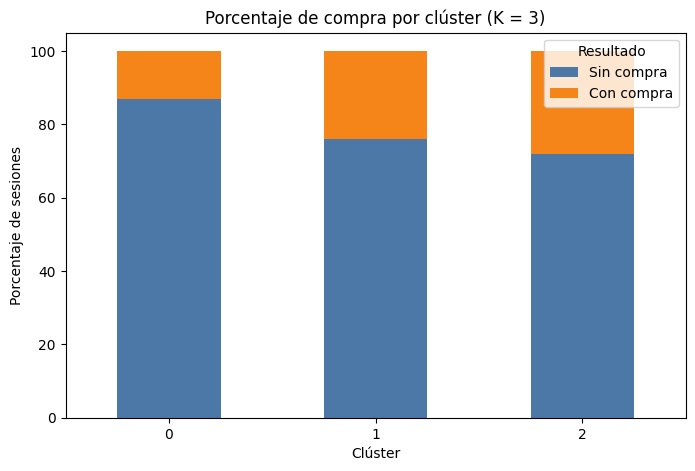

In [83]:
comparacion_revenue_k3.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"]
)

plt.title("Porcentaje de compra por clúster (K = 3)")
plt.xlabel("Clúster")
plt.ylabel("Porcentaje de sesiones")
plt.xticks(rotation=0)
plt.legend(title="Resultado")
plt.show()

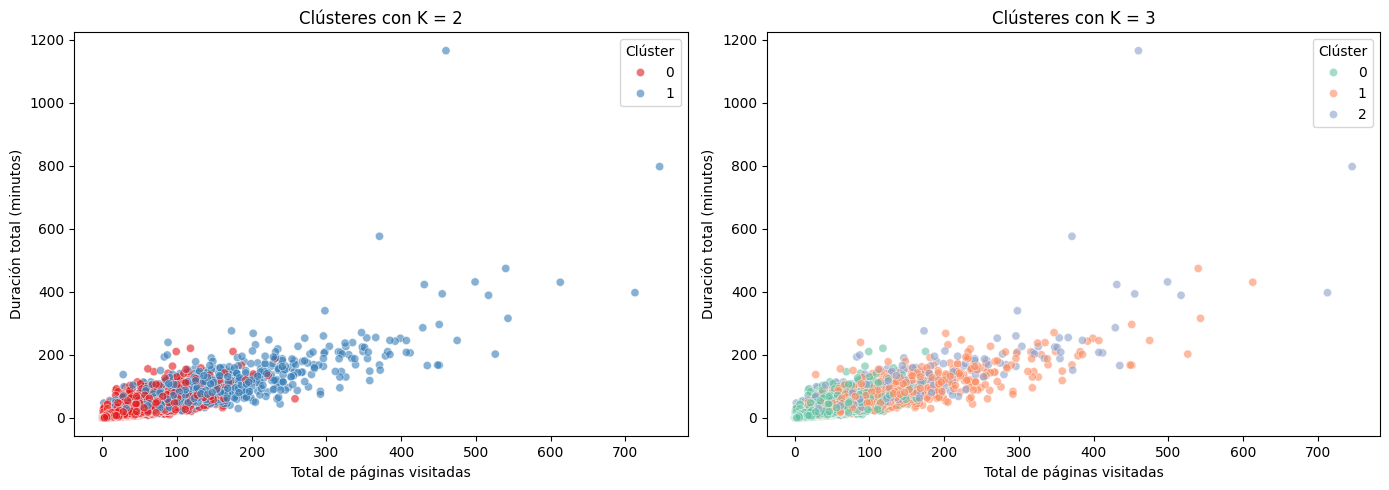

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter para K = 2
sns.scatterplot(
    data=df_clusters,
    x="Total_Pages",
    y="Total_Duration_min",
    hue="cluster_k2",
    palette="Set1",
    alpha=0.6,
    s=35,
    ax=axes[0]
)

axes[0].set_title("Clústeres con K = 2")
axes[0].set_xlabel("Total de páginas visitadas")
axes[0].set_ylabel("Duración total (minutos)")
axes[0].legend(title="Clúster")


# Scatter para K = 3
sns.scatterplot(
    data=df_clusters,
    x="Total_Pages",
    y="Total_Duration_min",
    hue="cluster_k3",
    palette="Set2",
    alpha=0.6,
    s=35,
    ax=axes[1]
)

axes[1].set_title("Clústeres con K = 3")
axes[1].set_xlabel("Total de páginas visitadas")
axes[1].set_ylabel("Duración total (minutos)")
axes[1].legend(title="Clúster")

plt.tight_layout()
plt.show()

Los gráficos muestran cómo se distribuyen los clústeres según la cantidad total de páginas visitadas y el tiempo total de navegación. En \(k=2\), las sesiones se dividen principalmente entre aquellas con menor actividad y aquellas con mayor número de páginas o duración. Con \(k=3\), uno de estos perfiles se divide para identificar un nivel intermedio de navegación. Sin embargo, puede existir superposición porque K-Means utilizó otras variables además de las representadas en el gráfico.

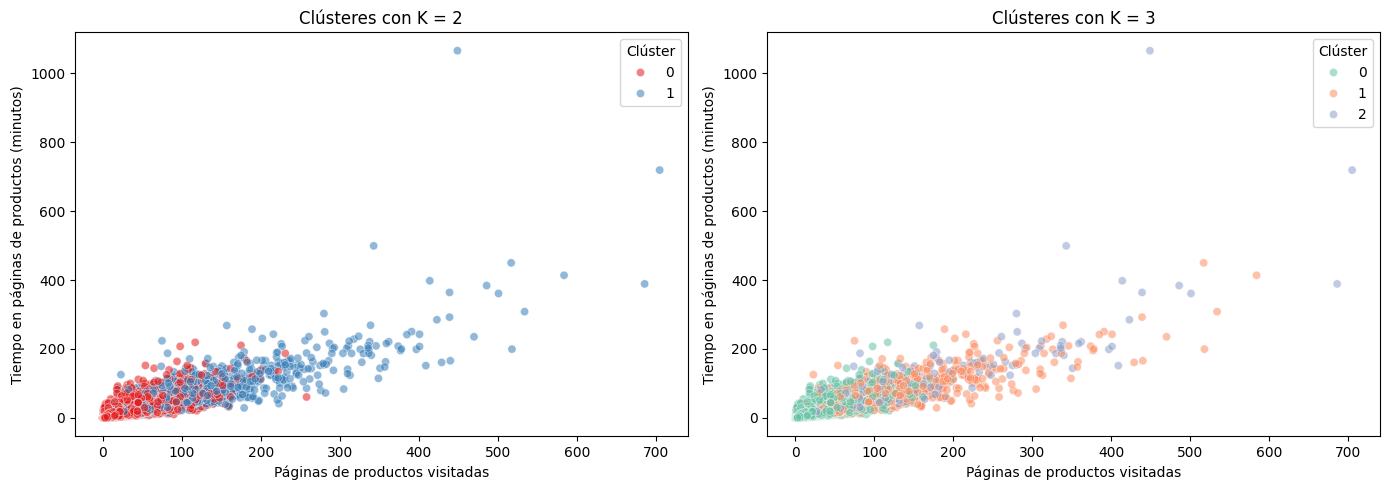

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K = 2
sns.scatterplot(
    data=df_clusters,
    x="ProductRelated",
    y="ProductRelated_Duration_min",
    hue="cluster_k2",
    palette="Set1",
    alpha=0.55,
    s=35,
    ax=axes[0]
)

axes[0].set_title("Clústeres con K = 2")
axes[0].set_xlabel("Páginas de productos visitadas")
axes[0].set_ylabel("Tiempo en páginas de productos (minutos)")
axes[0].legend(title="Clúster")


# K = 3
sns.scatterplot(
    data=df_clusters,
    x="ProductRelated",
    y="ProductRelated_Duration_min",
    hue="cluster_k3",
    palette="Set2",
    alpha=0.55,
    s=35,
    ax=axes[1]
)

axes[1].set_title("Clústeres con K = 3")
axes[1].set_xlabel("Páginas de productos visitadas")
axes[1].set_ylabel("Tiempo en páginas de productos (minutos)")
axes[1].legend(title="Clúster")

plt.tight_layout()
plt.show()

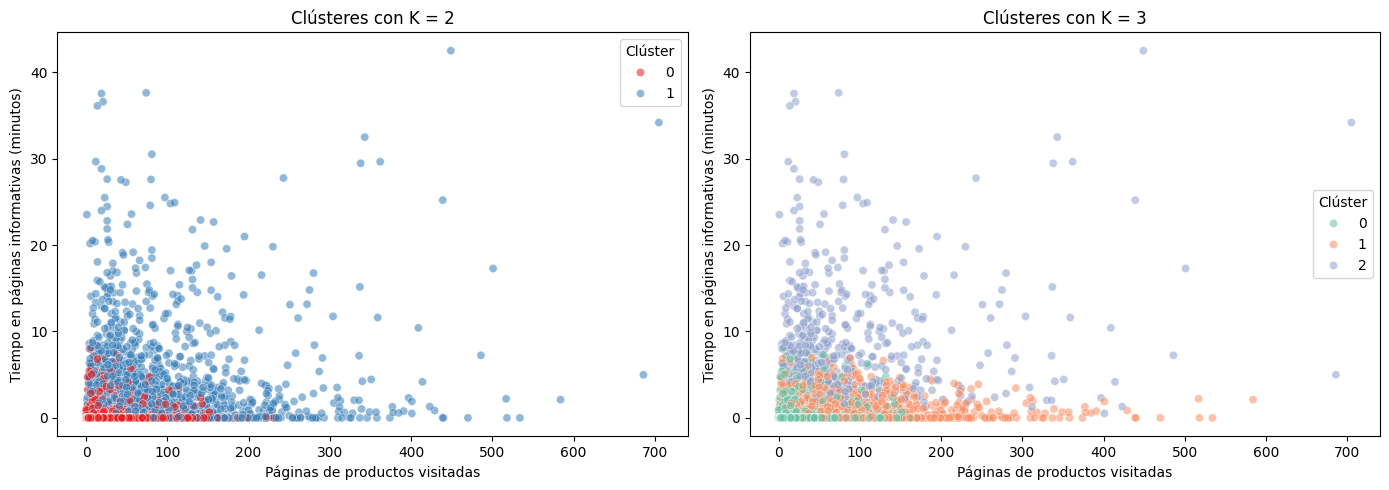

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K = 2
sns.scatterplot(
    data=df_clusters,
    x="ProductRelated",
    y="Informational_Duration_min",
    hue="cluster_k2",
    palette="Set1",
    alpha=0.55,
    s=35,
    ax=axes[0]
)

axes[0].set_title("Clústeres con K = 2")
axes[0].set_xlabel("Páginas de productos visitadas")
axes[0].set_ylabel("Tiempo en páginas informativas (minutos)")
axes[0].legend(title="Clúster")


# K = 3
sns.scatterplot(
    data=df_clusters,
    x="ProductRelated",
    y="Informational_Duration_min",
    hue="cluster_k3",
    palette="Set2",
    alpha=0.55,
    s=35,
    ax=axes[1]
)

axes[1].set_title("Clústeres con K = 3")
axes[1].set_xlabel("Páginas de productos visitadas")
axes[1].set_ylabel("Tiempo en páginas informativas (minutos)")
axes[1].legend(title="Clúster")

plt.tight_layout()
plt.show()

Selección del número de clústeres


Después de comparar las soluciones con 2, 3 y 4 clústeres, se seleccionó \(k=3\). Aunque \(k=2\) permite distinguir entre sesiones de baja y alta interacción, la solución con tres clústeres identifica un comportamiento adicional: sesiones que, además de visitar muchas páginas de productos, dedican mayor tiempo a consultar contenido informativo.

In [87]:
# Modelo K-Means definitivo con 3 clústeres
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_clusters["cluster_kmeans"] = kmeans_final.fit_predict(df_scaled)

df_clusters[[
    "Administrative",
    "Administrative_Duration_min",
    "Informational",
    "Informational_Duration_min",
    "ProductRelated",
    "cluster_kmeans"
]].head()

,Administrative,Administrative_Duration_min,Informational,Informational_Duration_min,ProductRelated,cluster_kmeans
0,0,0.00,0,0.00,1,0
1,0,0.00,0,0.00,2,0
2,0,0.00,0,0.00,1,0
3,0,0.00,0,0.00,2,0
4,0,0.00,0,0.00,10,0


Se construyó el modelo definitivo de K-Means utilizando tres clústeres. El modelo utilizó las cinco variables de comportamiento previamente seleccionadas y estandarizadas. Cada sesión fue asignada al clúster cuyo centroide se encuentra más cercano de acuerdo con la distancia euclidiana.

In [88]:
centroides = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=df_scaled.columns
)

centroides.round(2)

,Administrative,Administrative_Duration_min,Informational,Informational_Duration_min,ProductRelated
0,-0.40,-0.30,-0.26,-0.20,-0.25
1,1.48,1.13,0.39,0.05,0.80
2,1.22,0.96,3.30,3.68,1.36


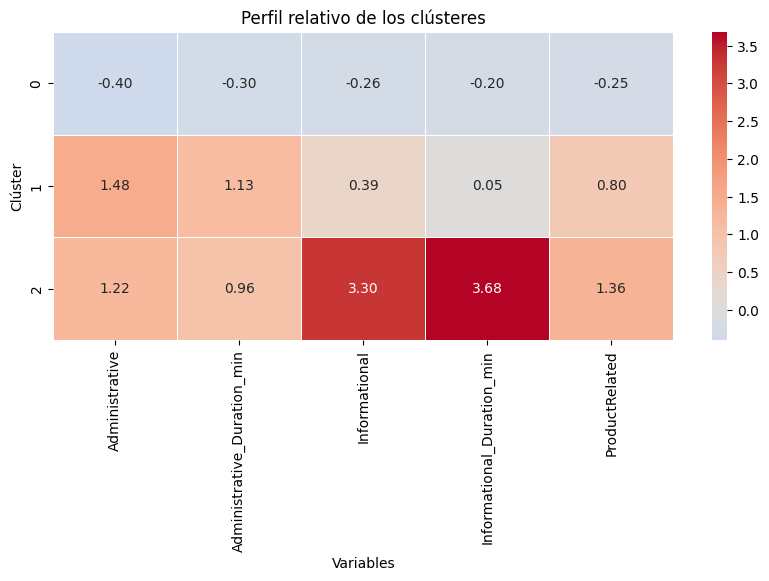

In [89]:
plt.figure(figsize=(10, 4))

sns.heatmap(
    centroides,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Perfil relativo de los clústeres")
plt.xlabel("Variables")
plt.ylabel("Clúster")
plt.show()

### Cómo leer esta gráfica

Ahí sí se lee rápido:
- rojo/positivo → por encima del promedio;
- azul/negativo → por debajo;
- cerca de 0 → parecido al promedio.

In [90]:
perfil_k3["porcentaje_sesiones"] = (
    perfil_k3["sesiones"] / len(df_clusters) * 100
).round(2)

perfil_k3

,sesiones,paginas_administrativas,tiempo_administrativo_min,paginas_informativas,tiempo_informativo_min,paginas_productos,porcentaje_compra,porcentaje_sesiones
cluster_k3,,,,,,,,
0,9560,1.02,0.46,0.18,0.11,20.92,13.11,78.33
1,2160,7.27,4.71,1.00,0.69,67.67,24.03,17.70
2,485,6.40,4.20,4.72,9.28,92.65,28.04,3.97


In [96]:
nombres_clusters = {
    0: "Baja interacción",
    1: "Exploración de productos",
    2: "Navegación intensiva e informativa"
}

df_clusters["segmento_kmeans"] = (
    df_clusters["cluster_kmeans"]
    .map(nombres_clusters)
)

df_clusters[[
    "cluster_kmeans",
    "segmento_kmeans"
]].sample(6)

,cluster_kmeans,segmento_kmeans
11037,0,Baja interacción
3297,0,Baja interacción
5444,0,Baja interacción
8119,2,Navegación intensiva e informativa
3623,0,Baja interacción
5089,0,Baja interacción


Clúster 0: Baja interacción


Este grupo concentra 9,560 sesiones, equivalentes al 78.33% del dataset. Presenta los valores más bajos en todas las variables: pocas páginas administrativas e informativas, tiempos de navegación reducidos y un promedio de 20.92 páginas de productos. También registra el menor porcentaje de compra, con 13.11%. Representa a los usuarios que realizan una exploración breve y poco profunda del sitio.


Clúster 1: Exploración de productos

Está formado por 2,160 sesiones, que representan el 17.70% del dataset. Estos usuarios muestran mayor actividad administrativa y visitan en promedio 67.67 páginas de productos, pero dedican poco tiempo al contenido informativo. Su porcentaje de compra es de 24.03%. Este grupo representa sesiones enfocadas principalmente en revisar productos y realizar acciones relacionadas con el proceso de compra.


Clúster 2: Navegación intensiva e informativa

Es el grupo más pequeño, con 485 sesiones, equivalentes al 3.97%. Se distingue por visitar la mayor cantidad de páginas de productos, con un promedio de 92.65, y por dedicar considerablemente más tiempo a las páginas informativas. Su porcentaje de compra es el más alto, con 28.04%. Representa a usuarios que realizan una investigación más profunda antes de tomar una decisión.

### Hallazgos

1. La intensidad de navegación está relacionada con la compra.
Las sesiones que terminaron en compra presentaron una mayor cantidad de páginas visitadas y una duración promedio superior. La segmentación automática confirmó esta relación: el clúster de baja interacción registró un 13.11% de compra, mientras que el perfil de navegación intensiva e informativa alcanzó un 28.04%.

2. Las sesiones atípicas representan usuarios con actividad especialmente alta.
Las sesiones clasificadas como atípicas visitaron en promedio 133.97 páginas y duraron 90.21 minutos, frente a 23.11 páginas y 13.95 minutos en las sesiones normales. Además, su tasa de compra fue de 27.68%, casi el doble que la de las sesiones normales, que fue de 14.20%. Por ello, estos casos no se eliminaron, ya que representan comportamientos reales y valiosos para el análisis.

3. Se identificaron tres perfiles de navegación.
K-Means permitió distinguir sesiones de baja interacción, sesiones enfocadas en la exploración de productos y sesiones con navegación intensiva e informativa. El perfil más pequeño, caracterizado por revisar más productos y dedicar mayor tiempo al contenido informativo, presentó el porcentaje de compra más alto.